In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix , classification_report , accuracy_score ,precision_score, recall_score, f1_score

In [3]:
df = pd.read_csv('breast_cancer_dataset (1).csv')

print ("veri boyutu :  ", df.shape)
df.head()

veri boyutu :   (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:
print(df['diagnosis'].value_counts)

<bound method IndexOpsMixin.value_counts of 0      M
1      M
2      M
3      M
4      M
      ..
564    M
565    M
566    M
567    M
568    B
Name: diagnosis, Length: 569, dtype: object>


In [6]:
df = df.drop(columns=['id', 'Unnamed: 32'])

In [7]:
df['diagosis'] = df['diagnosis'].map({'M':1, 'B':0})


print("Kalan boş değer sayısı:", df.isna().sum().sum())
print("Temizlenmiş veri boyutu : ",df.shape)
print("sınıf dağılımı : \n", df['diagnosis'].value_counts())

Kalan boş değer sayısı: 0
Temizlenmiş veri boyutu :  (569, 32)
sınıf dağılımı : 
 diagnosis
B    357
M    212
Name: count, dtype: int64


In [8]:
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

print("X boyutu : " , X.shape)
print("y boyutu : " , y.shape)

X boyutu :  (569, 31)
y boyutu :  (569,)


In [17]:
# X ve y değişkenlerini sayısal sınıflarla tekrar hazırlıyoruz
# 'diagosis' sayısal sütununu hedef değişken (y) olarak alıyoruz
X = df.drop(columns=['diagnosis', 'diagosis'])
y = df['diagosis']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Eğitim (Train) seti : {X_train.shape[0]} satır")
print(f"Doğrulama (Validation) seti : {X_val.shape[0]} satır")
print(f"Test seti : {X_test.shape[0]} satır")

Eğitim (Train) seti : 398 satır
Doğrulama (Validation) seti : 85 satır
Test seti : 86 satır


In [13]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Ölçeklendirme tamamlandı! Sayılar 0 ile 1 arasına sıkıştırıldı.")

Ölçeklendirme tamamlandı! Sayılar 0 ile 1 arasına sıkıştırıldı.


In [19]:
knn = KNeighborsClassifier(n_neighbors=5)


knn.fit(X_train_scaled, y_train)


y_pred_KNN = knn.predict(X_val_scaled)


print("--- k-NN Sonuçları ---")
print("Doğruluk (Accuracy):", accuracy_score(y_val, y_pred_KNN))
print("Duyarlılık (Recall):", recall_score(y_val, y_pred_KNN, pos_label=1))
print("Kesinlik (Precision):", precision_score(y_val, y_pred_KNN, pos_label=1))
print("F1 Skoru:", f1_score(y_val, y_pred_KNN, pos_label=1))

--- k-NN Sonuçları ---
Doğruluk (Accuracy): 1.0
Duyarlılık (Recall): 1.0
Kesinlik (Precision): 1.0
F1 Skoru: 1.0


In [22]:
dt = DecisionTreeClassifier(max_depth=3, random_state=42)
dt.fit(X_train_scaled, y_train)
y_pred_dt = dt.predict(X_val_scaled)


print("--- Karar Ağacı Sonuçları ---")
print("Doğruluk (Accuracy):", accuracy_score(y_val, y_pred_dt))
print("Duyarlılık (Recall):", recall_score(y_val, y_pred_dt))
print("Kesinlik (Precision):", precision_score(y_val, y_pred_dt))
print("F1 Skoru:", f1_score(y_val, y_pred_dt))

--- Karar Ağacı Sonuçları ---
Doğruluk (Accuracy): 1.0
Duyarlılık (Recall): 1.0
Kesinlik (Precision): 1.0
F1 Skoru: 1.0


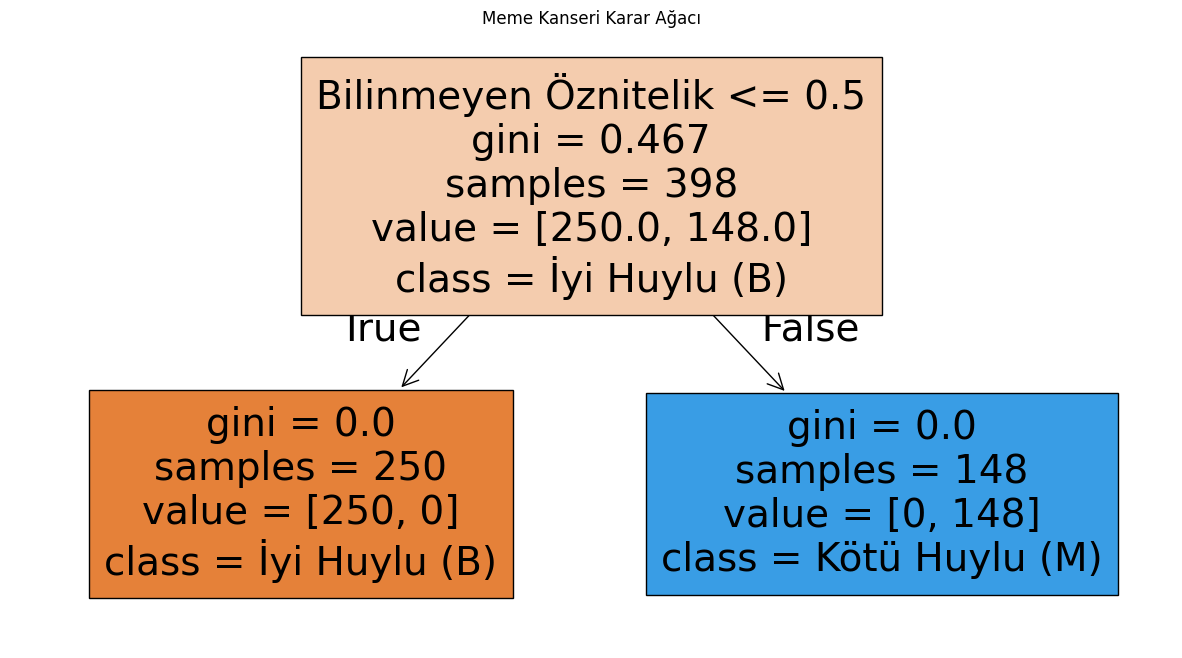

In [24]:
plt.figure(figsize=(15, 8))
# Sütun sayısı uyuşmazlığı hatasını engellemek için feature_names listesini dinamik olarak ayarlıyoruz
feature_names_list = list(X.columns) + ['Bilinmeyen Öznitelik'] if dt.n_features_in_ > len(X.columns) else list(X.columns)
plot_tree(dt, feature_names=feature_names_list, class_names=['İyi Huylu (B)', 'Kötü Huylu (M)'], filled=True)
plt.title("Meme Kanseri Karar Ağacı")
plt.show()

In [25]:

rf = RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42)


rf.fit(X_train, y_train)


y_pred_rf = rf.predict(X_val)

print("--- Random Forest Sonuçları ---")
print("Doğruluk (Accuracy):", accuracy_score(y_val, y_pred_rf))
print("Duyarlılık (Recall):", recall_score(y_val, y_pred_rf))
print("Kesinlik (Precision):", precision_score(y_val, y_pred_rf))
print("F1 Skoru:", f1_score(y_val, y_pred_rf))

--- Random Forest Sonuçları ---
Doğruluk (Accuracy): 0.9529411764705882
Duyarlılık (Recall): 0.875
Kesinlik (Precision): 1.0
F1 Skoru: 0.9333333333333333


In [27]:
# Karşılaştırma tablosu oluşturuyoruz
sonuclar = pd.DataFrame({
    'Model': ['k-NN', 'Karar Ağacı (Decision Tree)', 'Rastgele Orman (Random Forest)'],
    'Accuracy (Doğruluk)': [
        accuracy_score(y_val, y_pred_KNN),
        accuracy_score(y_val, y_pred_dt),
        accuracy_score(y_val, y_pred_rf)
    ],
    'Recall (Duyarlılık - Hayati!)': [
        recall_score(y_val, y_pred_KNN),
        recall_score(y_val, y_pred_dt),
        recall_score(y_val, y_pred_rf)
    ],
    'Precision (Kesinlik)': [
        precision_score(y_val, y_pred_KNN),
        precision_score(y_val, y_pred_dt),
        precision_score(y_val, y_pred_rf)
    ],
    'F1 Skoru': [
        f1_score(y_val, y_pred_KNN),
        f1_score(y_val, y_pred_dt),
        f1_score(y_val, y_pred_rf)
    ]
})

sonuclar

,Model,Accuracy (Doğruluk),Recall (Duyarlılık - Hayati!),Precision (Kesinlik),F1 Skoru
0,k-NN,1.000000,1.000,1.0,1.000000
1,Karar Ağacı (Decision Tree),1.000000,1.000,1.0,1.000000
2,Rastgele Orman (Random Forest),0.952941,0.875,1.0,0.933333


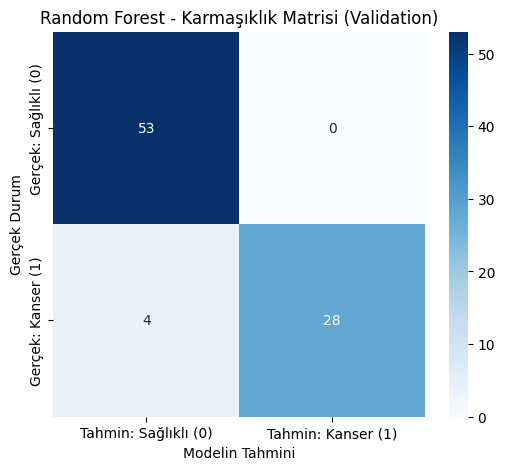

In [28]:
# En iyi modelin (Random Forest) karmaşıklık matrisi
cm = confusion_matrix(y_val, y_pred_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Tahmin: Sağlıklı (0)', 'Tahmin: Kanser (1)'],
            yticklabels=['Gerçek: Sağlıklı (0)', 'Gerçek: Kanser (1)'])
plt.title('Random Forest - Karmaşıklık Matrisi (Validation)')
plt.ylabel('Gerçek Durum')
plt.xlabel('Modelin Tahmini')
plt.show()